# Семинар 2. Что происходит внутри линейной модели

**Файлы для занятия.** Отдельный notebook без данных недостаточен.

| Файл | Для чего нужен |
|---|---|
| [seminar.ipynb](seminar.ipynb) | Текст, примеры, задания и проверки |
| [course_support.py](../course_support.py) | Готовые вспомогательные функции из комплекта ЛР1 |
| [data/tickets_lab1_dev.csv](../data/tickets_lab1_dev.csv) | Учебные обращения с известными ответами |
| [data/lab1_split.csv](../data/lab1_split.csv) | Заранее заданное разделение train / validation |
| [requirements.txt](../requirements.txt) | Зависимости Python для запуска |
| [data/DATA_CARD.md](../data/DATA_CARD.md) | Словарь полей и происхождение данных |

Первые четыре файла нужны при выполнении; зависимости устанавливаются заранее.
Ссылки относительные: они работают в распакованном комплекте, открытом через Jupyter из его корня.
Старый `intro_tickets.csv` для этого семинара не нужен. Данные из предыдущей выдачи ЛР1 не изменены.

На первом семинаре мы уже обучали `StandardScaler → Ridge`, считали MAE и меняли
подмножества признаков. Здесь следующий шаг: визуализация, небольшое MLE, единицы
коэффициентов, устойчивость модели и диагностика нелинейности.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import Math, display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

# Служебный поиск папки дан готовым; не является заданием.
ROOT = next(
    (
        p
        for p in [Path.cwd(), *Path.cwd().parents]
        if (
            (p / "course_support.py").is_file()
            and (p / "data/tickets_lab1_dev.csv").is_file()
        )
        or (
            (p / "materials/01-regression/code/course_support.py").is_file()
            and (
                p
                / "materials/02-data/datasets/support-tickets/student/tickets_lab1_dev.csv"
            ).is_file()
        )
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Распакуйте весь архив: нужны course_support.py и папка data/."
    )
DATA = (
    ROOT / "data"
    if (ROOT / "data/tickets_lab1_dev.csv").is_file()
    else ROOT / "materials/02-data/datasets/support-tickets/student"
)
SUPPORT = (
    ROOT
    if (ROOT / "course_support.py").is_file()
    else ROOT / "materials/01-regression/code"
)
if str(SUPPORT) not in sys.path:
    sys.path.insert(0, str(SUPPORT))
from course_support import (
    BLUE,
    CATEGORICAL,
    FEATURES,
    NUMERIC,
    TARGET,
    NormalizedRidge,
    baseline_pipeline,
    run_checks,
)

In [2]:
# Читаем только dev и разбиение. Test для семинара вообще не открываем.
dev = pd.read_csv(DATA / "tickets_lab1_dev.csv")
split = pd.read_csv(DATA / "lab1_split.csv")
assert dev.ticket_id.is_unique and split.ticket_id.is_unique
assert set(dev.ticket_id) == set(split.ticket_id)
assert set(split["split"]) == {"train", "validation"}
merged = dev.merge(split, on="ticket_id", how="left", validate="one_to_one")
train = (
    merged.loc[merged["split"] == "train"].drop(columns="split").reset_index(drop=True)
)
valid = (
    merged.loc[merged["split"] == "validation"]
    .drop(columns="split")
    .reset_index(drop=True)
)
assert len(train) + len(valid) == len(dev)
assert set(train.ticket_id).isdisjoint(set(valid.ticket_id))
X_train, y_train = train[FEATURES], train[TARGET].to_numpy()
X_valid, y_valid = valid[FEATURES], valid[TARGET].to_numpy()
checks = {}
print("Train / validation:", X_train.shape, X_valid.shape)
print("Ответ:", TARGET)

Train / validation: (1440, 9) (480, 9)
Ответ: resolution_minutes


`маркер=START`

Момент прогноза прежний: регистрация обращения. Все используемые поля доступны в этот момент.
Категории, пропуски и нелинейность здесь — свойства нового учебного набора,
не результат обогащения исходного CSV реальными сведениями о клиентах.

## Matplotlib: от чисел к графику
`маркер=PLOT`

`fig` — рисунок целиком; `ax` — область с координатами. Здесь у каждого рисунка одна область.
Создаём их через `fig, ax = plt.subplots()`, добавляем данные методами `ax`, затем вызываем
`plt.show()`. В Jupyter результат остаётся под ячейкой.

**Линия:** значения функции на упорядоченной сетке. Здесь это не данные обращений.
`np.linspace(a, b, n)` создаёт $n$ равномерных точек; `r"$...$"` позволяет записать
формулу в подписи через TeX-подобный синтаксис, без установленного LaTeX.

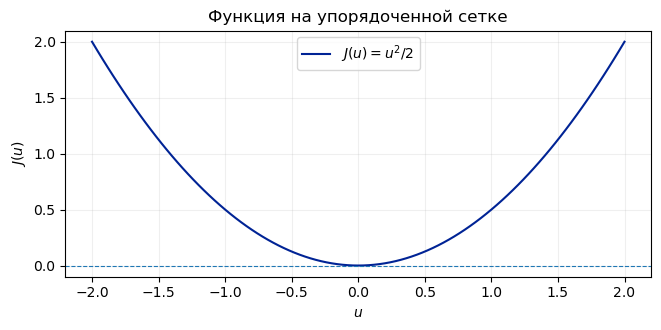

In [3]:
u = np.linspace(-2.0, 2.0, 101)
fig, ax = plt.subplots(figsize=(6.8, 3.4))
ax.plot(u, u**2 / 2, label=r"$J(u)=u^2/2$", color=BLUE)
ax.axhline(0, linestyle="--", linewidth=0.8)
ax.set(xlabel=r"$u$", ylabel=r"$J(u)$", title="Функция на упорядоченной сетке")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

**Точки:** каждая точка -- одно обращение из train. `s` задаёт площадь маркера,
`alpha` — прозрачность. Строки CSV не задают траекторию: через `plot` их соединять не нужно.
Подписи осей всегда сообщают величину и единицу измерения.

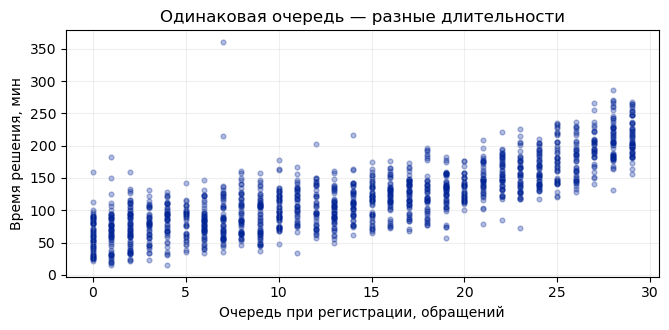

In [4]:
fig, ax = plt.subplots(figsize=(6.8, 3.4))
ax.scatter(train["queue_at_open"], train[TARGET], s=12, alpha=0.3, color=BLUE)
ax.set(
    xlabel="Очередь при регистрации, обращений",
    ylabel="Время решения, мин",
    title="Одинаковая очередь — разные длительности",
)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

**Гистограмма:** распределение одной числовой величины. `bins` — число интервалов,
а не число объектов. Ниже высота столбца — число обращений. При `density=True` нормируется
площадь, а вертикальная ось должна называться «Плотность», не «Число обращений».

Попробуйте разное число интервалов. Данные и среднее не поменялись

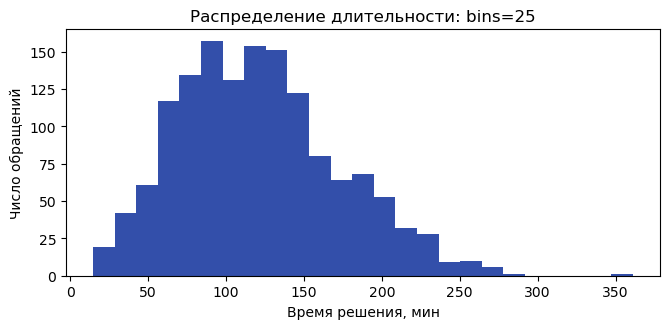

In [5]:
hist_bins = 25
fig, ax = plt.subplots(figsize=(6.8, 3.4))
ax.hist(train[TARGET], bins=hist_bins, alpha=0.8, color=BLUE)
ax.set(
    xlabel="Время решения, мин",
    ylabel="Число обращений",
    title=f"Распределение длительности: bins={hist_bins}",
)
fig.tight_layout()
plt.show()

**Boxplot:** сравнение распределений по категориям. Линия в коробке — медиана;
коробка — от 25-го до 75-го процентиля.

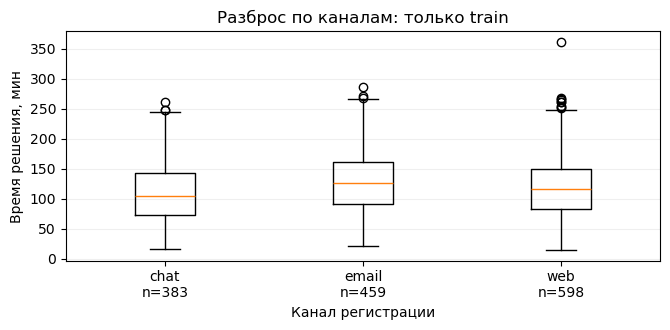

In [6]:
channels = sorted(train["channel"].dropna().unique())
channel_values = [train.loc[train["channel"] == c, TARGET].to_numpy() for c in channels]
fig, ax = plt.subplots(figsize=(6.8, 3.4))
ax.boxplot(
    channel_values,
    tick_labels=[f"{c}\nn={len(v)}" for c, v in zip(channels, channel_values)],
)
ax.set(
    xlabel="Канал регистрации",
    ylabel="Время решения, мин",
    title="Разброс по каналам: только train",
)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

Рисунок можно сохранить через `fig.savefig("my_plot.png", dpi=150, bbox_inches="tight")`.

## Вероятностная модель: исправляем сдвиг и оцениваем разброс
`маркер=MLE`

Дан **уже фиксированный** предсказатель $f_0(x)$. Веса $f_0$ сейчас не переобучаем.
Одной общей поправки может быть мало: у разных каналов регистрации ошибки могут
систематически отличаться. Найдём по одному сдвигу $c_g$ для каждого канала $g$.

Предположим независимые наблюдения

$$Y_i\mid x_i,g_i\sim\mathcal N\bigl(f_0(x_i)+c_{g_i},\ s\bigr),\qquad s=\sigma^2>0.$$

Здесь $s$ — общая дисперсия, не стандартное отклонение.
Для $r_i=f_0(x_i)-y_i$ и $I_g=\{i:g_i=g\}$:

$$\operatorname{NLL}(c,s)=\frac n2\log(2\pi s)
+\frac{1}{2s}\sum_g\sum_{i\in I_g}(r_i+c_g)^2.$$

NLL (Negative Log-Likelihood, отрицательное логарифмическое правдоподобие).
Сначала дифференцируем только по **одной** поправке $c_g$: остальные слагаемые
от неё не зависят. Это обычная производная квадрата и решение одного уравнения.

Куда нам идти? Прогноз 10, факт 13. Остаток $r=-3$; чтобы приблизиться к факту,
надо **прибавить** положительную поправку.

In [7]:
# Четыре вымышленных наблюдения; это отдельный пример, не строки из CSV.
mle_prediction = np.array([10.0, 20.0, 30.0, 40.0])
mle_y = np.array([13.0, 21.0, 34.0, 42.0])
mle_groups = np.array(["chat", "chat", "email", "email"])
display(
    pd.DataFrame(
        {
            "канал": mle_groups,
            "прогноз": mle_prediction,
            "факт": mle_y,
            "r = прогноз − факт": mle_prediction - mle_y,
        }
    )
)

# Словарь хранит отдельное значение для каждого ключа. Это только пример синтаксиса.
example_lookup = {"chat": 10, "email": 20}
print("Известный ключ:", example_lookup.get("chat", 0))
print("Новый ключ, значение по умолчанию:", example_lookup.get("phone", 0))
print("Маска chat:", mle_groups == "chat")

,канал,прогноз,факт,r = прогноз − факт
0,chat,10.0,13.0,-3.0
1,chat,20.0,21.0,-1.0
2,email,30.0,34.0,-4.0
3,email,40.0,42.0,-2.0


Известный ключ: 10
Новый ключ, значение по умолчанию: 0
Маска chat: [ True  True False False]


Напишите две функции; ориентир - 15–20 строк основной логики.

Сначала получите $\widehat c_g$ из $\partial\operatorname{NLL}/\partial c_g=0$.
Для общей резервной поправки $c_0$ используйте ту же формулу, рассматривая все
объекты как одну группу. Достаточно записать производную и один переход к ответу.

В `fit_group_corrections(y, prediction, groups)`:
- вычислите остатки и общую поправку;
- пройдите циклом по каналам, сохраните их поправки в словарь и исправьте остатки;
- вычислите $\widehat s=\frac1n\sum_i(r_i+\widehat c_{g_i})^2$;
- верните `{"global_correction": число, "corrections": словарь, "variance": число}`.

В `apply_group_corrections(prediction, groups, fitted)` создайте **новый** массив
прогнозов. Известному каналу добавьте его поправку, неизвестному — общую.
Для нового канала это заданное резервное правило, а не найденный по его данным MLE.
Ответы `y` при применении не передаются.

Все входы — одномерные массивы одинаковой ненулевой длины; числа конечны,
каналы — строки. После поправок остаётся ненулевой разброс. Проверку этих
предпосылок писать не требуется. Циклы, `sorted(set(groups))`, маски и `.get`
достаточны; `groupby`, broadcasting и классы scikit-learn не нужны.

**Сложнее.** Защитите малые группы от большой случайной поправки:
при фиксированной общей поправке $c_0$ минимизируйте для каждого канала
$\sum_{i\in I_g}(r_i+c_g)^2+\kappa(c_g-c_0)^2$.
Получите формулу через одну производную, добавьте параметр `kappa` и сравните
`kappa=0`, `5`, `30` на одном и том же разбиении. Сжимайте поправки к общему
сдвигу, а не к нулю. Выбор `kappa` по validation не является независимым тестом.

In [8]:
def fit_group_corrections(y, prediction, groups):
    r = prediction - y
    global_correction = -np.mean(r)
    corrections = {}
    for g in set(groups):
        mask = groups == g
        corrections[g] = -np.mean(r[mask])
    corrected_r = np.empty_like(r)
    for i, g in enumerate(groups):
        corrected_r[i] = r[i] + corrections[g]
    variance = np.mean(corrected_r**2)
    return {
        "global_correction": global_correction,
        "corrections": corrections,
        "variance": variance,
    }


def apply_group_corrections(prediction, groups, fitted):
    result = prediction.copy()
    for i, g in enumerate(groups):
        if g in fitted["corrections"]:
            result[i] += fitted["corrections"][g]
        else:
            result[i] += fitted["global_correction"]
    return result


mle_explanation = ""

**Проверка кода.** Проверяем числа, разные размеры групп и применение к неизвестному каналу.

In [9]:
def check_mle():
    fitted = fit_group_corrections(mle_y, mle_prediction, mle_groups)
    np.testing.assert_allclose(
        [fitted["corrections"]["chat"], fitted["corrections"]["email"]], [2.0, 3.0]
    )
    np.testing.assert_allclose(
        [fitted["global_correction"], fitted["variance"]], [2.5, 1.0]
    )
    before = mle_prediction.copy()
    corrected = apply_group_corrections(mle_prediction, mle_groups, fitted)
    np.testing.assert_allclose(corrected, [12.0, 22.0, 33.0, 43.0])
    np.testing.assert_array_equal(mle_prediction, before)
    new = apply_group_corrections(
        np.array([10.0, 10.0]), np.array(["phone", "email"]), fitted
    )
    np.testing.assert_allclose(new, [12.5, 13.0])
    # Дисперсия усредняется по объектам, а не поровну по группам.
    unequal = fit_group_corrections(
        np.array([0.0, 2.0, 1.0, 3.0, 5.0, 7.0]),
        np.zeros(6),
        np.array(["a", "a", "b", "b", "b", "b"]),
    )
    np.testing.assert_allclose(unequal["variance"], 11 / 3)
    shifted = fit_group_corrections(mle_y + 7, mle_prediction, mle_groups)
    np.testing.assert_allclose(shifted["variance"], fitted["variance"])
    np.testing.assert_allclose(
        shifted["global_correction"], fitted["global_correction"] + 7
    )


checks["MLE"] = run_checks("MLE групповых поправок", check_mle)
if checks["MLE"]:
    toy_correction = fit_group_corrections(mle_y, mle_prediction, mle_groups)
    print("Оценённые параметры:", toy_correction)

MLE групповых поправок: проверки пройдены (это не автоматическая итоговая оценка).
Оценённые параметры: {'global_correction': np.float64(2.5), 'corrections': {np.str_('chat'): np.float64(2.0), np.str_('email'): np.float64(3.0)}, 'variance': np.float64(1.0)}


Применим обе функции в небольшом эксперименте. Готовая числовая модель намеренно
не использует канал регистрации. Первую часть **train** используем для её весов,
вторую -- для поправок. Validation не участвует ни в одном из этих обучений.
Это один заранее заданный разрез train, не кросс-валидация.

In [10]:
# Готовая обвязка: не пишем новый линейный решатель и не меняем исходное разбиение.
mle_columns = ["message_length", "queue_at_open", "account_age_days"]
mle_fit = train.iloc[:1000]
mle_calibration = train.iloc[1000:]
mle_model = make_pipeline(
    SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=30.0, solver="svd")
).fit(mle_fit[mle_columns], mle_fit[TARGET])
calibration_prediction = mle_model.predict(mle_calibration[mle_columns])
calibration_y = mle_calibration[TARGET].to_numpy()
calibration_groups = mle_calibration["channel"].fillna("unknown").to_numpy()
mle_valid_prediction = mle_model.predict(valid[mle_columns])
mle_valid_groups = valid["channel"].fillna("unknown").to_numpy()
if checks["MLE"]:
    fitted_correction = fit_group_corrections(
        calibration_y, calibration_prediction, calibration_groups
    )
    corrected_variants = {
        "Без поправки": mle_valid_prediction,
        "Общая поправка": mle_valid_prediction + fitted_correction["global_correction"],
        "По каналам": apply_group_corrections(
            mle_valid_prediction, mle_valid_groups, fitted_correction
        ),
    }
    mle_rows = []
    for name, pred in corrected_variants.items():
        mle_rows.append(
            {
                "модель": name,
                "RMSE, мин": np.sqrt(np.mean((pred - y_valid) ** 2)),
                "средний остаток, мин": np.mean(pred - y_valid),
            }
        )
    mle_results = pd.DataFrame(mle_rows)
    display(mle_results)

,модель,"RMSE, мин","средний остаток, мин"
0,Без поправки,20.200428,1.472493
1,Общая поправка,20.200230,1.469775
2,По каналам,19.922909,1.786249


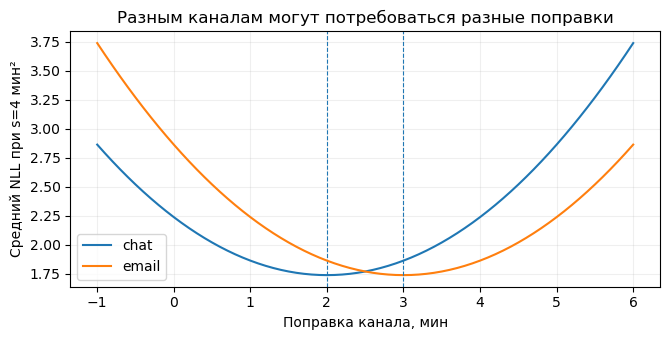

In [11]:
# При фиксированном s каждый c_g отвечает за собственную параболу NLL.
correction_grid = np.linspace(-1, 6, 141)
fig, ax = plt.subplots(figsize=(6.8, 3.5))
for group in sorted(set(mle_groups)):
    group_residual = (mle_prediction - mle_y)[mle_groups == group]
    values = [
        0.5 * np.log(2 * np.pi * 4.0) + np.mean((group_residual + c) ** 2) / 8.0
        for c in correction_grid
    ]
    ax.plot(correction_grid, values, label=group)
    if checks["MLE"]:
        ax.axvline(toy_correction["corrections"][group], linestyle="--", linewidth=0.8)
ax.set(
    xlabel="Поправка канала, мин",
    ylabel="Средний NLL при s=4 мин²",
    title="Разным каналам могут потребоваться разные поправки",
)
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Коэффициент изменился, а предсказатель?
`маркер=SCALE`

На train нашли $\mu_j,s_j$ и обучили модель в стандартных координатах:

$$z_j=\frac{x_j-\mu_j}{s_j},\qquad \widehat y=b_z+\sum_j w_{z,j}z_j.$$

Нужно получить ту же функцию в исходных единицах. Для пропусков под x подразумеваем заполненную
train-медианой таблицу. Сам scaler нормальность распределения не обеспечивает.

Пример: $z=(x-100)/20$, $\widehat y=10+2z=0+0.1x$.
Вес поменялся, но одинаковому объекту должен соответствовать одинаковый прогноз.

In [12]:
numeric_columns = ["message_length", "queue_at_open", "account_age_days"]
imputer = SimpleImputer(strategy="median").fit(train[numeric_columns])
filled_train = imputer.transform(train[numeric_columns])
filled_valid = imputer.transform(valid[numeric_columns])
scaler = StandardScaler().fit(filled_train)
scaled_train = scaler.transform(filled_train)
scaled_valid = scaler.transform(filled_valid)
scaled_model = Ridge(alpha=30.0, solver="svd").fit(scaled_train, y_train)
prediction_scaled = scaled_model.predict(scaled_valid)
display(
    pd.DataFrame(
        {
            "поле": numeric_columns,
            "mean_train": scaler.mean_,
            "scale_train": scaler.scale_,
            "w_scaled": scaled_model.coef_,
        }
    )
)

,поле,mean_train,scale_train,w_scaled
0,message_length,883.093056,496.963932,19.886770
1,queue_at_open,13.998611,8.823343,40.711024
2,account_age_days,727.522917,393.864898,3.606779


In [13]:
# Один уже заполненный объект; размеры изменений выбраны для эксперимента заранее.
scenario_x = filled_valid[0].copy()
scenarios = {
    "Без изменений": np.array([0.0, 0.0, 0.0]),
    "+100 символов": np.array([100.0, 0.0, 0.0]),
    "+5 в очереди": np.array([0.0, 5.0, 0.0]),
    "+365 дней": np.array([0.0, 0.0, 365.0]),
    "Очередь и длинное сообщение": np.array([100.0, 5.0, 0.0]),
}
print("Порядок признаков:", numeric_columns)
print("Исходный объект:", scenario_x)

Порядок признаков: ['message_length', 'queue_at_open', 'account_age_days']
Исходный объект: [1244.    0.  653.]


Напишите преобразование коэффициентов, циклы допустимы.

Подставьте $z_j=(x_j-\mu_j)/s_j$ в прогноз и выразите новые веса и свободный член.
Затем вычтите прогноз в $x$ из прогноза в $x+\Delta x$: какая часть формулы останется?

`to_original_units(weights, intercept, means, scales)` возвращает новые веса и новое $b$.
Все масштабы положительны, как `scaler.scale_`; исходные массивы менять нельзя.

`scenario_table(weights, intercept, x, changes, feature_names)` получает **уже
пересчитанные** коэффициенты и словарь `{имя: вектор изменений}`. Для каждого сценария:
- создайте изменённый объект и вычислите прогнозы до и после;
- вычислите изменение прогноза и отдельные вклады $w_j\Delta x_j$;
- назовите признак с наибольшим вкладом **по модулю**; если все вклады нулевые — `"нет"`;
- добавьте строку в таблицу с колонками `scenario`, `before`, `after`, `delta`, `largest_feature`.

При равенстве модулей можно брать первый признак. `np.argmax(np.abs(contributions))`
даёт его индекс. Отчёт — обычный список словарей и `pd.DataFrame(rows)`.
Изменения могут затрагивать несколько признаков одновременно; не ограничивайтесь
тремя отдельными умножениями. Все сценарии применяются к исходному `x`, а не друг за другом.

In [14]:
def to_original_units(weights, intercept, means, scales):
    w_orig = weights / scales
    b_orig = intercept - np.sum(weights * means / scales)
    return w_orig, b_orig


def scenario_table(weights, intercept, x, changes, feature_names):
    rows = []
    for name, delta in changes.items():
        x_new = x + delta
        before = intercept + np.dot(weights, x)
        after = intercept + np.dot(weights, x_new)
        delta_pred = after - before
        contributions = weights * delta
        if np.allclose(contributions, 0):
            largest = "нет"
        else:
            idx = np.argmax(np.abs(contributions))
            largest = feature_names[idx]
        rows.append({
            "scenario": name,
            "before": before,
            "after": after,
            "delta": delta_pred,
            "largest_feature": largest,
        })
    return pd.DataFrame(rows)


units_explanation = ""

**Проверка кода.** Проверяем ту же функцию, совместные изменения признаков и отсутствие изменения входа.

In [15]:
def check_units():
    w, b = to_original_units(
        scaled_model.coef_, scaled_model.intercept_, scaler.mean_, scaler.scale_
    )
    np.testing.assert_allclose(b + filled_valid @ w, prediction_scaled, atol=1e-9)
    before = scenario_x.copy()
    table = scenario_table(w, b, scenario_x, scenarios, numeric_columns)
    assert list(table.columns) == [
        "scenario",
        "before",
        "after",
        "delta",
        "largest_feature",
    ]
    assert list(table["scenario"]) == list(scenarios)
    np.testing.assert_array_equal(scenario_x, before)
    expected = []
    for change in scenarios.values():
        original_pred = scaled_model.predict(scaler.transform([scenario_x]))[0]
        new_pred = scaled_model.predict(scaler.transform([scenario_x + change]))[0]
        expected.append(new_pred - original_pred)
    np.testing.assert_allclose(table["delta"], expected, atol=1e-9)
    assert table.iloc[0]["largest_feature"] == "нет"
    small = scenario_table(
        np.array([2.0, -1.0]),
        5.0,
        np.array([10.0, 4.0]),
        {"mixed": np.array([2.0, 3.0])},
        ["length", "queue"],
    )
    np.testing.assert_allclose(
        small[["before", "after", "delta"]].to_numpy(), [[21.0, 22.0, 1.0]]
    )
    assert small.iloc[0]["largest_feature"] == "length"


checks["SCALE"] = run_checks("Исходные единицы и сценарии", check_units)
if checks["SCALE"]:
    weights_original, intercept_original = to_original_units(
        scaled_model.coef_, scaled_model.intercept_, scaler.mean_, scaler.scale_
    )
    scenario_results = scenario_table(
        weights_original, intercept_original, scenario_x, scenarios, numeric_columns
    )
    display(scenario_results)

Исходные единицы и сценарии: проверки пройдены (это не автоматическая итоговая оценка).


,scenario,before,after,delta,largest_feature
0,Без изменений,70.302513,70.302513,0.000000,нет
1,+100 символов,70.302513,74.304165,4.001653,message_length
2,+5 в очереди,70.302513,93.372580,23.070067,queue_at_open
3,+365 дней,70.302513,73.644964,3.342451,account_age_days
4,Очередь и длинное сообщение,70.302513,97.374232,27.071719,queue_at_open


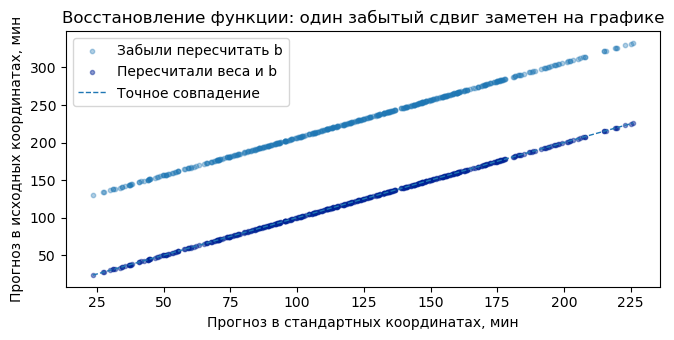

In [16]:
if checks["SCALE"]:
    restored_prediction = intercept_original + filled_valid @ weights_original
    wrong_prediction = scaled_model.intercept_ + filled_valid @ weights_original
    fig, ax = plt.subplots(figsize=(6.8, 3.5))
    ax.scatter(
        prediction_scaled,
        wrong_prediction,
        s=10,
        alpha=0.35,
        label="Забыли пересчитать b",
    )
    ax.scatter(
        prediction_scaled,
        restored_prediction,
        s=9,
        alpha=0.45,
        color=BLUE,
        label="Пересчитали веса и b",
    )
    limits = [float(prediction_scaled.min()), float(prediction_scaled.max())]
    ax.plot(limits, limits, linestyle="--", linewidth=1, label="Точное совпадение")
    ax.set(
        xlabel="Прогноз в стандартных координатах, мин",
        ylabel="Прогноз в исходных координатах, мин",
        title="Восстановление функции: один забытый сдвиг заметен на графике",
    )
    ax.legend()
    fig.tight_layout()
    plt.show()

## Коэффициенты нестабильны, а прогнозы?
`маркер=RIDGE-STABILITY`

Длина сообщения и размер первого запроса несут близкую информацию. При $x_1=x_2$
веса $(100,-99)$ и $(1,0)$ задают одну линейную часть $x_1$.
Проверяем **чувствительность к изменению train-ответов**.

Фиксируем X, scaler, проверочные объекты и набор возмущений. Каждый раз обучаем модель
на $y+\delta$. Для всех значений регуляризации возмущения одни и те же.
Предобработка не меняется: в этом опыте меняется только y.

Используем критерий $\mathrm{MSE}+\lambda\|w\|^2$, поэтому для sklearn Ridge
передаём `alpha=n_train*lambda`

В этом задании измерим чувствительность **относительно модели без возмущения**,
а не через `std` заранее приготовленного массива.
Для каждой $\lambda$ есть опорные веса $w^{(0)}$ и прогнозы $p^{(0)}$.
После добавления шума к train-ответам получим $w^{(k)},p^{(k)}$.

Сравним среднее расстояние между весами, среднее изменение прогнозов и среднюю RMSE:

$$D_w=\frac1R\sum_k\sqrt{\sum_j(w_j^{(k)}-w_j^{(0)})^2},\qquad
D_p=\frac1R\sum_k\sqrt{\frac1m\sum_i(p_i^{(k)}-p_i^{(0)})^2},$$
$$\overline{\mathrm{RMSE}}=\frac1R\sum_k\sqrt{\frac1m\sum_i(p_i^{(k)}-y_i)^2}.$$

Здесь три разные величины. В $D_p$ сравниваем **два прогноза**, в RMSE — прогноз
с правильным ответом. Эти расстояния не являются оценкой дисперсии из теоремы
bias–variance и не должны называться ею.

In [17]:
correlated = ["message_length", "initial_payload_bytes", "queue_at_open"]
stability_train = train.dropna(subset=correlated).iloc[:100]
stability_valid = valid.dropna(subset=correlated)
stability_scaler = StandardScaler().fit(stability_train[correlated])
SX = stability_scaler.transform(stability_train[correlated])
SV = stability_scaler.transform(stability_valid[correlated])
sy = stability_train[TARGET].to_numpy()
sv_y = stability_valid[TARGET].to_numpy()
noise_matrix = np.random.default_rng(37).normal(0.0, 3.0, size=(12, len(sy)))


def fit_small_ridge(X, y, l2):
    """Готово: одно обучение библиотечной модели для MSE + l2 * ||w||²."""
    return Ridge(alpha=len(y) * l2, solver="svd").fit(X, y)


example_model = fit_small_ridge(SX, sy, 0.03)
print("coef_:", example_model.coef_)
print("Первые прогнозы:", example_model.predict(SV)[:3])
print("Возмущений:", len(noise_matrix), "| Каждое имеет форму:", noise_matrix[0].shape)
print("Корреляция первых двух признаков:", np.corrcoef(SX[:, 0], SX[:, 1])[0, 1])

coef_: [ 9.94626321 11.05628001 42.88842394]
Первые прогнозы: [ 71.96948982 126.28134753  49.39420554]
Возмущений: 12 | Каждое имеет форму: (100,)
Корреляция первых двух признаков: 0.9998710385914699


Напишите `stability_experiment` - небольшой эксперимент.

Для каждого `l2`:
- обучите опорную модель на неизменённом `y_fit`, сохраните её прогнозы;
- пройдите циклом по строкам `noise`, обучая новую модель на `y_fit + delta`;
- посчитайте расстояние до опорных весов, изменение прогнозов и RMSE на `y_check`;
- усредните три списка чисел и добавьте одну строку в итоговую таблицу.

Верните колонки `l2`, `coef_change`, `prediction_change`, `mean_rmse` в порядке
переданных `lambdas`. Модель обучается только на `x_fit`, `y_fit + delta`.
`y_check` нужен лишь для RMSE. Предобработка и все возмущения уже готовы:
новый шум внутри цикла создавать не нужно, исходный `y_fit` менять нельзя.

Используйте готовую `fit_small_ridge`, обычные `for`, списки и `np.mean`, `np.sum`,
`np.sqrt`. Никакого клонирования estimator, новых классов, CV или операций
с трёхмерными массивами не требуется.

**Сложнее.** Повторите опыт для всех непустых подмножеств трёх признаков — всего семь
наборов. Сохраните те же строки, шум и значения lambda; сравните RMSE и изменение
прогнозов. Добавьте в таблицу имя набора и поделитесь двумя интересными компромиссами.
Меньший разброс весов разных размерностей не используйте как рейтинг важности признаков.

In [18]:
def stability_experiment(lambdas, noise, x_fit, x_check, y_fit, y_check):
    rows = []
    for l2 in lambdas:
        base_model = fit_small_ridge(x_fit, y_fit, l2)
        base_pred = base_model.predict(x_check)
        base_coef = base_model.coef_
        coef_changes = []
        pred_changes = []
        rmse_values = []
        for delta in noise:
            model = fit_small_ridge(x_fit, y_fit + delta, l2)
            pred = model.predict(x_check)
            coef = model.coef_
            coef_changes.append(np.linalg.norm(coef - base_coef))
            pred_changes.append(np.sqrt(np.mean((pred - base_pred) ** 2)))
            rmse_values.append(np.sqrt(np.mean((pred - y_check) ** 2)))
        rows.append({
            "l2": l2,
            "coef_change": np.mean(coef_changes),
            "prediction_change": np.mean(pred_changes),
            "mean_rmse": np.mean(rmse_values),
        })
    return pd.DataFrame(rows)


stability_explanation = ""

**Проверка кода.** При нулевом возмущении модель не меняется. Ошибка при этом может быть ненулевой.

In [19]:
def check_stability():
    zero = stability_experiment([0.0, 0.1], np.zeros((2, len(sy))), SX, SV, sy, sv_y)
    assert list(zero.columns) == ["l2", "coef_change", "prediction_change", "mean_rmse"]
    np.testing.assert_allclose(
        zero[["coef_change", "prediction_change"]], 0, atol=1e-10
    )
    for i, l2 in enumerate([0.0, 0.1]):
        pred = fit_small_ridge(SX, sy, l2).predict(SV)
        np.testing.assert_allclose(
            zero.iloc[i]["mean_rmse"], np.sqrt(np.mean((pred - sv_y) ** 2))
        )
    before = sy.copy()
    one = stability_experiment([0.03], noise_matrix[:1], SX, SV, sy, sv_y)
    base = fit_small_ridge(SX, sy, 0.03)
    changed = fit_small_ridge(SX, sy + noise_matrix[0], 0.03)
    # Другая запись формулы: длина вектора, делённая на корень из числа объектов.
    expected = np.linalg.norm(changed.predict(SV) - base.predict(SV)) / np.sqrt(len(SV))
    np.testing.assert_allclose(one.iloc[0]["prediction_change"], expected)
    np.testing.assert_array_equal(sy, before)


checks["STABILITY"] = run_checks(
    "Собственный эксперимент с возмущениями", check_stability
)
if checks["STABILITY"]:
    stability_summary = stability_experiment(
        [0.0, 0.03, 1.0, 100.0], noise_matrix, SX, SV, sy, sv_y
    )
    display(stability_summary)

Собственный эксперимент с возмущениями: проверки пройдены (это не автоматическая итоговая оценка).


,l2,coef_change,prediction_change,mean_rmse
0,0.00,19.552452,0.536693,20.191514
1,0.03,0.298845,0.438328,20.117679
2,1.00,0.153812,0.360255,29.156778
3,100.00,0.003503,0.311551,48.837946


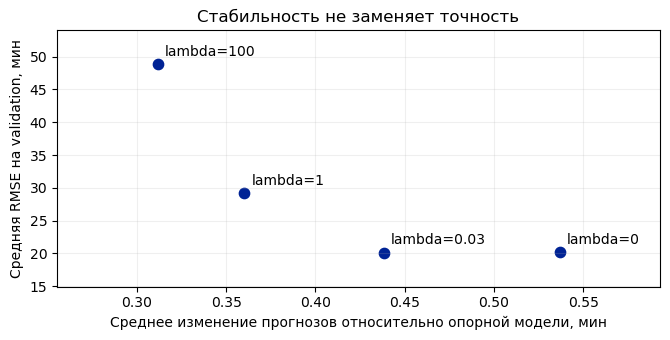

In [20]:
if checks["STABILITY"]:
    fig, ax = plt.subplots(figsize=(6.8, 3.5))
    ax.scatter(
        stability_summary["prediction_change"],
        stability_summary["mean_rmse"],
        s=55,
        color=BLUE,
    )
    for _, row in stability_summary.iterrows():
        ax.annotate(
            f"lambda={row['l2']:g}",
            (row["prediction_change"], row["mean_rmse"]),
            xytext=(5, 6),
            textcoords="offset points",
        )
    ax.margins(x=0.25, y=0.18)
    ax.set(
        xlabel="Среднее изменение прогнозов относительно опорной модели, мин",
        ylabel="Средняя RMSE на validation, мин",
        title="Стабильность не заменяет точность",
    )
    ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()

## Проблема не в оптимизаторе?
`маркер=RESIDUALS`

Линейная модель может быть корректно обучена и всё равно систематически промахиваться.
Остаток здесь $r=\widehat y-y$: **отрицательный** остаток означает недооценку времени.
Сначала посмотрим готовый baseline на validation. Гипотезы ниже фиксированы заранее;
validation теперь используется для сравнения, а не является финальным test.

In [21]:
residual_baseline = baseline_pipeline(l2=0.03).fit(X_train, y_train)
residual_prediction = residual_baseline.predict(X_valid)
queue_valid = valid["queue_at_open"].to_numpy()
print("RMSE baseline, мин:", np.sqrt(np.mean((residual_prediction - y_valid) ** 2)))

RMSE baseline, мин: 15.311857936378965


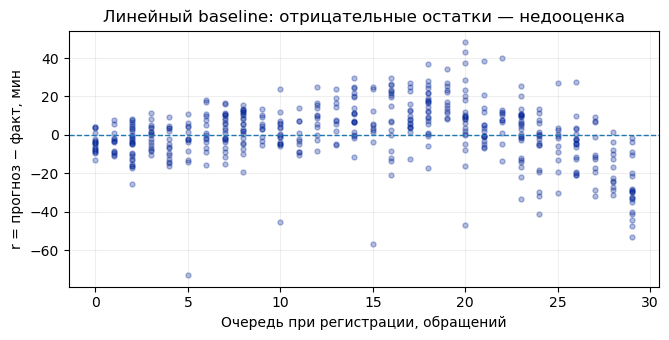

In [22]:
fig, ax = plt.subplots(figsize=(6.8, 3.5))
ax.scatter(queue_valid, residual_prediction - y_valid, s=13, alpha=0.3, color=BLUE)
ax.axhline(0, linestyle="--", linewidth=1)
ax.set(
    xlabel="Очередь при регистрации, обращений",
    ylabel="r = прогноз − факт, мин",
    title="Линейный baseline: отрицательные остатки — недооценка",
)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

Сравним четыре заранее заданных набора: без новых признаков, только $h_1$, только
$h_2$ и оба вместе. В каждом случае обучается **новая** модель на тех же train-строках.

$$h_1(q)=\max(q-18,0),\qquad h_2(q)=\max(q-18,0)^2.$$

Пример: при $q=20$ имеем $h_1=2$, $h_2=4$; при $q=18$ оба нулевые.
`np.maximum(values, 0)` применяет максимум к каждому элементу и сохраняет NaN.
Пропуски затем заполняются внутри обучаемой цепочки.

In [23]:
def make_feature_model(extra_columns, l2=0.03):
    """Готовая фабрика: возвращает новую модель с выбранными дополнительными столбцами.

    Внутреннее устройство ColumnTransformer не является заданием.
    На вход fit/predict подаётся таблица, уже расширенная вашей функцией.
    """
    numeric = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    categorical = make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
    )
    columns = ColumnTransformer(
        [
            ("numeric", numeric, NUMERIC + list(extra_columns)),
            ("category", categorical, CATEGORICAL),
        ],
        sparse_threshold=0,
    )
    return make_pipeline(columns, NormalizedRidge(l2=l2))


feature_sets = {
    "Базовое": [],
    "+ h1": ["h1"],
    "+ h2": ["h2"],
    "+ h1 + h2": ["h1", "h2"],
}
# Знакомый интерфейс; ниже такой цикл по наборам вы напишете сами.
example_feature_model = make_feature_model([])
print(
    "У новой модели есть fit и predict:",
    hasattr(example_feature_model, "fit"),
    hasattr(example_feature_model, "predict"),
)

У новой модели есть fit и predict: True True


**Самостоятельно: 10 минут.** Реализуйте две функции. Ориентир — примерно 20 строк
основной логики, не считая оформления словарей и подписей.

`add_queue_features(frame)` возвращает **копию** таблицы с двумя столбцами `h1`, `h2`.
Исходную таблицу и её индекс не меняйте. NaN в очереди должен остаться NaN в новых полях.

`compare_feature_sets(x_fit, y_fit, x_check, y_check, feature_sets, l2=0.03)` получает
уже расширенные таблицы. В цикле по заданным наборам:
- создайте новую модель через `make_feature_model`, обучите её и получите прогнозы;
- вычислите остатки $r=\hat y-y$;
- посчитайте RMSE по всем объектам, RMSE при $q>18$, средний остаток в этой группе и её размер;
- сохраните строку отчёта и сами прогнозы.

Верните пару `(table, predictions)`: колонки таблицы — `model`, `rmse_all`,
`rmse_high`, `mean_residual_high`, `n_high`; `predictions` — словарь `{имя: массив}`.
Если группа пуста, её две метрики равны `np.nan`, размер — нулю.

Сравните выбор по общей ошибке и по ошибке большой очереди. После основной проверки
скопируйте scatter выше и замените только вектор прогнозов на одну выбранную модель.
Это небольшая практика Matplotlib, а не требование писать функцию построения графиков.

**Сложнее.** Добавьте $h_3(q)=\log(1+q)$ и сравните все восемь подмножеств трёх новых
признаков, включая пустое. Используйте тот же цикл, те же строки и `l2`; найдите
два набора с близкой общей ошибкой, но различающейся ошибкой большой очереди.
Фабрика уже принимает произвольный список добавленных столбцов. Порог 18 не подбирайте
по результатам и не удаляйте неудобные объекты. Оба уровня — выбор по validation, не test.

In [24]:
def add_queue_features(frame):
    result = frame.copy()
    q = result["queue_at_open"]
    h1 = np.maximum(q - 18, 0)
    h2 = h1 ** 2
    result["h1"] = h1
    result["h2"] = h2
    return result


def compare_feature_sets(x_fit, y_fit, x_check, y_check, feature_sets, l2=0.03):
    rows = []
    predictions = {}
    for name, extra_cols in feature_sets.items():
        model = make_feature_model(extra_cols, l2=l2)
        model.fit(x_fit, y_fit)
        pred = model.predict(x_check)
        predictions[name] = pred
        r = pred - y_check
        rmse_all = np.sqrt(np.mean(r ** 2))
        high = x_check["queue_at_open"].to_numpy() > 18
        n_high = int(high.sum())
        if n_high > 0:
            rmse_high = np.sqrt(np.mean(r[high] ** 2))
            mean_residual_high = np.mean(r[high])
        else:
            rmse_high = np.nan
            mean_residual_high = np.nan
        rows.append({
            "model": name,
            "rmse_all": rmse_all,
            "rmse_high": rmse_high,
            "mean_residual_high": mean_residual_high,
            "n_high": n_high,
        })
    return pd.DataFrame(rows), predictions


feature_hypothesis = ""

**Проверка кода.** Проверяем не победителя, а формулы, границу $q=18$,
пропуск, сохранение исходной таблицы и отдельное обучение для каждого набора.

In [25]:
def check_feature_and_groups():
    tiny = pd.DataFrame(
        {"queue_at_open": [17.0, 18.0, 20.0, np.nan], "other": [1, 2, 3, 4]},
        index=[4, 1, 8, 9],
    )
    before = tiny.copy(deep=True)
    transformed = add_queue_features(tiny)
    np.testing.assert_allclose(transformed["h1"], [0, 0, 2, np.nan], equal_nan=True)
    np.testing.assert_allclose(transformed["h2"], [0, 0, 4, np.nan], equal_nan=True)
    pd.testing.assert_frame_equal(tiny, before)
    pd.testing.assert_frame_equal(transformed[tiny.columns], tiny)
    a = add_queue_features(X_train.iloc[:60])
    b = add_queue_features(X_valid.iloc[:12])
    y = y_valid[:12]
    table, predictions = compare_feature_sets(
        a, y_train[:60], b, y, {"Базовое": [], "+ h2": ["h2"]}
    )
    assert list(table.columns) == [
        "model",
        "rmse_all",
        "rmse_high",
        "mean_residual_high",
        "n_high",
    ]
    assert list(table["model"]) == ["Базовое", "+ h2"]
    high = b["queue_at_open"].to_numpy() > 18
    for i, name in enumerate(["Базовое", "+ h2"]):
        p = predictions[name]
        np.testing.assert_allclose(
            table.iloc[i]["rmse_all"], np.sqrt(np.mean((p - y) ** 2))
        )
        assert table.iloc[i]["n_high"] == int(high.sum())
        if high.any():
            np.testing.assert_allclose(
                table.iloc[i]["rmse_high"], np.sqrt(np.mean((p[high] - y[high]) ** 2))
            )
    independent = make_feature_model(["h2"]).fit(a, y_train[:60]).predict(b)
    np.testing.assert_allclose(predictions["+ h2"], independent)
    # Проверочная группа может отсутствовать — её качество не равно нулю.
    no_high = X_valid.iloc[:3].copy()
    no_high["queue_at_open"] = 0.0
    empty, _ = compare_feature_sets(
        a, y_train[:60], add_queue_features(no_high), y_valid[:3], {"a": []}
    )
    assert empty.iloc[0]["n_high"] == 0 and np.isnan(empty.iloc[0]["rmse_high"])


checks["FEATURE"] = run_checks(
    "Собственные признаки и цикл сравнения", check_feature_and_groups
)
if checks["FEATURE"]:
    feature_train = add_queue_features(X_train)
    feature_valid = add_queue_features(X_valid)
    feature_results, feature_predictions = compare_feature_sets(
        feature_train, y_train, feature_valid, y_valid, feature_sets
    )
    display(feature_results)

Собственные признаки и цикл сравнения: проверки пройдены (это не автоматическая итоговая оценка).


,model,rmse_all,rmse_high,mean_residual_high,n_high
0,Базовое,15.311858,18.954205,-2.839313,176
1,+ h1,12.683964,14.351619,0.557617,176
2,+ h2,12.588389,14.536507,-1.852783,176
3,+ h1 + h2,12.555763,14.228760,-0.784451,176


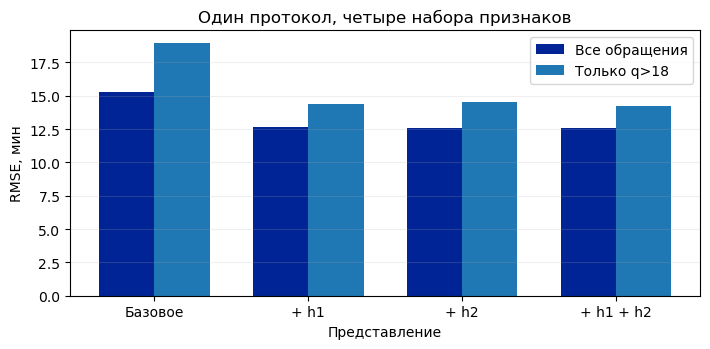

In [26]:
if checks["FEATURE"]:
    positions = np.arange(len(feature_results))
    fig, ax = plt.subplots(figsize=(7.2, 3.6))
    ax.bar(
        positions - 0.18,
        feature_results["rmse_all"],
        width=0.36,
        label="Все обращения",
        color=BLUE,
    )
    ax.bar(
        positions + 0.18, feature_results["rmse_high"], width=0.36, label="Только q>18"
    )
    ax.set_xticks(positions, feature_results["model"])
    ax.set(
        xlabel="Представление",
        ylabel="RMSE, мин",
        title="Один протокол, четыре набора признаков",
    )
    ax.legend()
    ax.grid(axis="y", alpha=0.2)
    fig.tight_layout()
    plt.show()

При обоих новых признаках модель имеет вид
$$\widehat y=b+w^\top x+u_1h_1(q)+u_2h_2(q).$$
Она остаётся линейной по обучаемым параметрам.

Общая ошибка — не гарантия одинакового качества в каждой группе. Укажите число обращений
в группе и не называйте разницу причинным эффектом. Все оценки здесь относятся к этой
учебной validation; выбор между h1 и h2 уже использует её ответы.

Для самостоятельной диагностики скопируйте scatter выше и замените только вектор прогноза
на `feature_predictions["+ h2"]`. Не меняйте разбиение и не удаляйте неудобные объекты.

In [27]:
print("Основные блоки:", checks)
print(
    "Полностью завершено по автоматическим проверкам:",
    len(checks) == 4 and all(checks.values()),
)

Основные блоки: {'MLE': True, 'SCALE': True, 'STABILITY': True, 'FEATURE': True}
Полностью завершено по автоматическим проверкам: True


## Результат и выводы
`маркер=FINISH`

1. Понимаем как из производной получилась поправка для одного каналаэ.
2. Почему при возвращении в исходные единицы пришлось изменить и веса, и свободный член.
3. Точность vs стабильность?
4. Посмотрели validation vs test
6. Немного посмотрели графики наживую

Сохраните notebook и выполните **Restart Kernel → Run All**. Зелёная проверка означает
прохождение конечного набора тестов, а не полноту письменного объяснения.
Не нужно отдельно сдавать семинар на 10 баллов: баллы относятся к ЛР1.